## Preparação de Dados

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

from sklearn.linear_model import LinearRegression

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

import time

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import matplotlib.pyplot as plt

#### Carregando o dataset

In [2]:
data = pd.read_csv('/datasets/car_data.csv')
data.head()

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,24/03/2016 11:52,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,24/03/2016 00:00,0,70435,07/04/2016 03:16
1,24/03/2016 10:58,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,24/03/2016 00:00,0,66954,07/04/2016 01:46
2,14/03/2016 12:52,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,14/03/2016 00:00,0,90480,05/04/2016 12:47
3,17/03/2016 16:54,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,17/03/2016 00:00,0,91074,17/03/2016 17:40
4,31/03/2016 17:25,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,31/03/2016 00:00,0,60437,06/04/2016 10:17


#### Informações gerais

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   DateCrawled        354369 non-null  object
 1   Price              354369 non-null  int64 
 2   VehicleType        316879 non-null  object
 3   RegistrationYear   354369 non-null  int64 
 4   Gearbox            334536 non-null  object
 5   Power              354369 non-null  int64 
 6   Model              334664 non-null  object
 7   Mileage            354369 non-null  int64 
 8   RegistrationMonth  354369 non-null  int64 
 9   FuelType           321474 non-null  object
 10  Brand              354369 non-null  object
 11  NotRepaired        283215 non-null  object
 12  DateCreated        354369 non-null  object
 13  NumberOfPictures   354369 non-null  int64 
 14  PostalCode         354369 non-null  int64 
 15  LastSeen           354369 non-null  object
dtypes: int64(7), object(

#### Estatistica descritiva

In [4]:
data.describe()

,Price,RegistrationYear,Power,Mileage,RegistrationMonth,NumberOfPictures,PostalCode
count,354369.000000,354369.000000,354369.000000,354369.000000,354369.000000,354369.0,354369.000000
mean,4416.656776,2004.234448,110.094337,128211.172535,5.714645,0.0,50508.689087
std,4514.158514,90.227958,189.850405,37905.341530,3.726421,0.0,25783.096248
min,0.000000,1000.000000,0.000000,5000.000000,0.000000,0.0,1067.000000
25%,1050.000000,1999.000000,69.000000,125000.000000,3.000000,0.0,30165.000000
50%,2700.000000,2003.000000,105.000000,150000.000000,6.000000,0.0,49413.000000
75%,6400.000000,2008.000000,143.000000,150000.000000,9.000000,0.0,71083.000000
max,20000.000000,9999.000000,20000.000000,150000.000000,12.000000,0.0,99998.000000


#### Verificando valores ausentes

In [5]:
missing = data.isna().sum()

missing[missing > 0]

VehicleType    37490
Gearbox        19833
Model          19705
FuelType       32895
NotRepaired    71154
dtype: int64

#### Substituindo valores ausentes

In [6]:
categorical_columns = [
    'VehicleType',
    'Gearbox',
    'Model',
    'FuelType',
    'NotRepaired'
]
# Aqui eu optei por substituir todos os valores ausentes por a string 'unknown' pois todas são variáves categóricas.
for column in categorical_columns:
    data[column] = data[column].fillna('unknown')

In [7]:
# Verificando novamente os valores ausentes
data.isna().sum()

DateCrawled          0
Price                0
VehicleType          0
RegistrationYear     0
Gearbox              0
Power                0
Model                0
Mileage              0
RegistrationMonth    0
FuelType             0
Brand                0
NotRepaired          0
DateCreated          0
NumberOfPictures     0
PostalCode           0
LastSeen             0
dtype: int64

#### Verificando duplicatas

In [8]:
data.duplicated().sum()

262

In [9]:
# Removendo as linhas duplicadas 
data = data.drop_duplicates().reset_index(drop=True)

In [10]:
# Verificando novamente as linhas duplicadas 
data.duplicated().sum()

0

#### Analisando a nova variavel alvo - Preço

In [11]:
data['Price'].describe()

count    354107.000000
mean       4416.433287
std        4514.338584
min           0.000000
25%        1050.000000
50%        2700.000000
75%        6400.000000
max       20000.000000
Name: Price, dtype: float64

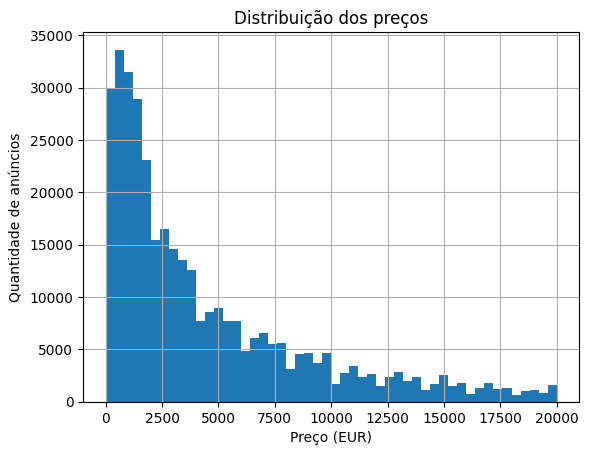

In [12]:
# Criando um histograma para facilitar a visualização
data['Price'].hist(bins=50)

plt.title('Distribuição dos preços')
plt.xlabel('Preço (EUR)')
plt.ylabel('Quantidade de anúncios')
plt.show()

In [13]:
# Removendo os carro que tem o preço igual a 0
data = data[data['Price'] > 0].reset_index(drop = True)

Os registros com Power = 0 foram removidos, pois esse valor não representa uma potência real de um veículo e provavelmente indica ausência ou inconsistência no dado. Optou-se pela remoção dessas linhas em vez da imputação, pois a substituição poderia introduzir valores artificiais nos dados.

#### Verificando valores estranhos de variaveis importantes

In [14]:
# Ano 
data['RegistrationYear'].describe()

count    343337.000000
mean       2004.090573
std          78.442725
min        1000.000000
25%        1999.000000
50%        2003.000000
75%        2008.000000
max        9999.000000
Name: RegistrationYear, dtype: float64

In [15]:
# Filtrando para uma faixa mais razoável
# Consideramos apenas anos de registro entre 1900 e 2016.
# 1900 foi usado como limite inferior para remover valores
# claramente inválidos, enquanto 2016 é o ano máximo sustentado
# pelo período de coleta dos anúncios.
data = data[(data['RegistrationYear'] >= 1900) & (data['RegistrationYear'] <= 2016)].reset_index(drop=True)

In [16]:
# Potência 
data['Power'].describe()

count    329506.000000
mean        111.898114
std         184.915789
min           0.000000
25%          71.000000
50%         105.000000
75%         143.000000
max       20000.000000
Name: Power, dtype: float64

In [17]:
# Filtrando para uma faixa mais razoável
# Analisando a distribuição da potência
print(data['Power'].describe(percentiles=[0.90, 0.95, 0.99, 0.995, 0.999]))

# Verificando os maiores valores
print(data['Power'].sort_values(ascending=False).head(20))

# Quantidade de valores iguais a zero
print('Quantidade de Power = 0:', (data['Power'] == 0).sum())
print('Porcentagem de Power = 0:', (data['Power'] == 0).mean() * 100)

# Remover valores de potência acima do limite definido
antes = len(data)

data = data[data['Power'] <= 600]

print('Linhas removidas por Power > 600:', antes - len(data))

# Remover valores de potência iguais a zero
antes = len(data)

data = data[data['Power'] > 0]

print('Linhas removidas por Power = 0:', antes - len(data))


count    329506.000000
mean        111.898114
std         184.915789
min           0.000000
50%         105.000000
90%         182.000000
95%         218.000000
99%         300.000000
99.5%       334.000000
99.9%       600.495000
max       20000.000000
Name: Power, dtype: float64
204186    20000
278229    19312
106194    19211
123314    19208
59498     17932
182785    17700
140212    17410
174247    17019
163176    17011
201790    16312
289621    16311
168650    16051
191403    15033
138143    15020
242530    15017
150947    15001
252022    14009
211649    13636
199174    13616
174847    12684
Name: Power, dtype: int64
Quantidade de Power = 0: 32860
Porcentagem de Power = 0: 9.972504294307235
Linhas removidas por Power > 600: 330
Linhas removidas por Power = 0: 32860


A análise dos percentis mostrou que aproximadamente 99,9% dos veículos possuem potência de até 600 hp. Por isso, foi utilizado o limite de 600 hp para remover valores extremos que poderiam influenciar negativamente o treinamento dos modelos. Os registros com Power = 0 também foram removidos, pois esse valor não representa uma potência real de um veículo e provavelmente indica ausência ou inconsistência no dado.

A variável Power apresenta alguns valores muito elevados. A análise dos percentis mostrou que aproximadamente 99,9% dos veículos possuem potência de até 600 hp. Por isso, foi utilizado o limite de 600 hp para remover valores extremos que poderiam influenciar negativamente o treinamento dos modelos.

#### Removendo colunas que não são necessario para o treinamento do modelo

In [18]:
data = data.drop(
    ['DateCrawled', 'DateCreated', 'LastSeen', 'NumberOfPictures'],
    axis=1
)

In [19]:
print(data.columns.tolist())

['Price', 'VehicleType', 'RegistrationYear', 'Gearbox', 'Power', 'Model', 'Mileage', 'RegistrationMonth', 'FuelType', 'Brand', 'NotRepaired', 'PostalCode']


## Treinamento do modelo

#### Separando features e target

In [20]:
features = data.drop('Price', axis=1)
target = data['Price']

In [21]:
print(features.columns.tolist())

['VehicleType', 'RegistrationYear', 'Gearbox', 'Power', 'Model', 'Mileage', 'RegistrationMonth', 'FuelType', 'Brand', 'NotRepaired', 'PostalCode']


#### Verificando variáveis que não ajudam o modelo 

In [22]:
data.nunique()

Price                3591
VehicleType             9
RegistrationYear       89
Gearbox                 3
Power                 435
Model                 250
Mileage                13
RegistrationMonth      13
FuelType                8
Brand                  40
NotRepaired             3
PostalCode           8116
dtype: int64

O resultado mostra que nenhuma das colunas restantes é constante, pois todas possuem pelo menos 3 valores distintos. A coluna NumberOfPictures, que era constante, já foi removida anteriormente.



#### Preparando variávies categóricas 

In [23]:
features = pd.get_dummies(
    features,
    columns=['VehicleType', 'Gearbox', 'Model', 'FuelType', 'Brand', 'NotRepaired'],
    drop_first=True
)

As variáveis PostalCode e RegistrationMonth foram mantidas como características dos modelos. Embora PostalCode seja uma variável numérica com muitos valores distintos e não represente uma ordem numérica, ela pode conter informações relacionadas à localização do veículo. Já RegistrationMonth foi mantida por poder fornecer informações relacionadas ao período de registro do veículo. Portanto, essas variáveis foram utilizadas de forma consistente nos diferentes modelos avaliados.

#### Separando treino, validação e teste

In [24]:
# Treino = 60%
#Temporario = 40%
features_train, features_temp, target_train, target_temp = train_test_split(
    features, 
    target, 
    test_size = 0.4,
    random_state = 12345)

In [25]:
#Dividindo o temporario 
features_valid, features_test, target_valid, target_test = train_test_split(
    features_temp,
    target_temp,
    test_size=0.5,
    random_state=12345
)
# Treino = 60%
# Validação = 20%
# Teste = 20

#### Treinando o modelo - Regressão Linear
##### Baseline

In [26]:
# Treinando o modelo e descobrindo o tempo de treinamento
model_lr = LinearRegression()

start = time.time()

model_lr.fit(features_train, target_train)

training_time_lr = time.time() - start

In [27]:
# Predizendo o modelo e e descobrindo o tempo para fazer a predição

start = time.time()

predictions_lr = model_lr.predict(features_valid)

prediction_time_lr = time.time() - start

In [28]:
# Calculando o REQM
rmse_lr = mean_squared_error(
    target_valid,
    predictions_lr
) ** 0.5

In [29]:
print('REQM:', rmse_lr)
print('Tempo de treinamento:', training_time_lr)
print('Tempo de previsão:', prediction_time_lr)

REQM: 2595.0932872435164
Tempo de treinamento: 6.094498872756958
Tempo de previsão: 0.12442827224731445


#### Árvore de Decisão

In [30]:
# Treinando o modelo e descobrindo o tempo de treinamento
model_tree = DecisionTreeRegressor(
    max_depth=15,
    random_state=12345
)
start = time.time()

model_tree.fit(features_train, target_train)

training_time_tree = time.time() - start

In [31]:
# Predizendo o modelo e e descobrindo o tempo para fazer a predição
start = time.time()

predictions_tree = model_tree.predict(features_valid)

prediction_time_tree = time.time() - start

In [32]:
# Calculando o REQM
rmse_tree = mean_squared_error(
    target_valid,
    predictions_tree
) ** 0.5

#### Testando alguns max_depht

In [33]:
tree_results = []

for depth in [5, 10, 15, 20]:

    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=12345
    )

    # Tempo de treinamento
    start = time.time()
    model.fit(features_train, target_train)
    training_time = time.time() - start

    # Tempo de previsão
    start = time.time()
    predictions = model.predict(features_valid)
    prediction_time = time.time() - start

    # RMSE
    rmse = mean_squared_error(
        target_valid,
        predictions
    ) ** 0.5

    tree_results.append({
        'max_depth': depth,
        'RMSE': rmse,
        'Training Time': training_time,
        'Prediction Time': prediction_time
    })

tree_results = pd.DataFrame(tree_results).reset_index(drop = True)
tree_results

,max_depth,RMSE,Training Time,Prediction Time
0,5,2438.974751,1.327717,0.068498
1,10,1998.016707,2.250250,0.070275
2,15,1909.417552,2.861435,0.076061
3,20,1957.109835,3.334830,0.081587


In [34]:
print('REQM:', rmse_tree)
print('Tempo de treinamento:', training_time_tree)
print('Tempo de previsão:', prediction_time_tree)

REQM: 1909.4175519671132
Tempo de treinamento: 2.95378041267395
Tempo de previsão: 0.07551717758178711


#### Floresta aleatória

In [35]:
# Treinando o modelo e descobrindo o tempo de treinamento
model_rf = RandomForestRegressor(
    n_estimators=10,
    max_depth=15,
    random_state=12345,
    n_jobs=2
)

start = time.time()

model_rf.fit(features_train, target_train)

training_time_rf = time.time() - start

In [36]:
# Predizendo o modelo e e descobrindo o tempo para fazer a predição
start = time.time()

predictions_rf = model_rf.predict(features_valid)

prediction_time_rf = time.time() - start

In [37]:
# Calculando o REQM 
rmse_rf = mean_squared_error(
    target_valid,
    predictions_rf
) ** 0.5

#### Testando alguns hiperparâmetros para a floresta

In [38]:
n_estimators_list = [50, 100]
max_depth_list = [10, 20]

results_rf = []

for n_estimators in n_estimators_list:
    for max_depth in max_depth_list:
        print(f"Treinando: {n_estimators} árvores, profundidade {max_depth}")
        
        model = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            random_state=12345,
            n_jobs=2
        )
        
        start = time.time()
        model.fit(features_train, target_train)
        training_time = time.time() - start
        
        start = time.time()
        predictions = model.predict(features_valid)
        prediction_time = time.time() - start
        
        rmse = mean_squared_error(
            target_valid,
            predictions
        ) ** 0.5
        
        results_rf.append({
            'n_estimators': n_estimators,
            'max_depth': max_depth,
            'rmse': rmse,
            'training_time': training_time,
            'prediction_time': prediction_time
        })
        

Treinando: 50 árvores, profundidade 10
Treinando: 50 árvores, profundidade 20
Treinando: 100 árvores, profundidade 10
Treinando: 100 árvores, profundidade 20


In [39]:
results_table = pd.DataFrame(results_rf)
print(results_table)

   n_estimators  max_depth         rmse  training_time  prediction_time
0            50         10  1905.986573      35.300682         0.168827
1            50         20  1617.311648      52.609315         0.371025
2           100         10  1903.010084      70.700222         0.260697
3           100         20  1613.033469     101.742084         0.693917


#### Pegando os melhores resultados

In [40]:
best_rf = results_table.loc[results_table['rmse'].idxmin()]

rmse_rf_best = best_rf['rmse']
training_time_rf_best = best_rf['training_time']
prediction_time_rf_best = best_rf['prediction_time']

#### Mostrando resultados


In [41]:
print('REQM:', rmse_rf)
print('Tempo de treinamento:', training_time_rf)
print('Tempo de previsão:', prediction_time_rf)

REQM: 1722.6172109364493
Tempo de treinamento: 8.779634714126587
Tempo de previsão: 0.10832381248474121


#### LightGBM

In [42]:
model_lgbm = LGBMRegressor(
    n_estimators=20,
    learning_rate=0.1,
    max_depth=10,
    random_state=12345,
    num_leaves=127,
    n_jobs=2
)

In [43]:
# Treinando o modelo e descobrindo quanto tempo leva 
start = time.time()

model_lgbm.fit(features_train, target_train)

training_time_lgbm = time.time() - start

In [44]:
# Predizendo o modelo e e descobrindo o tempo para fazer a predição
start = time.time()

predictions_lgbm = model_lgbm.predict(features_valid)

prediction_time_lgbm = time.time() - start

In [45]:
# Calculando o REQM
rmse_lgbm = mean_squared_error(
    target_valid,
    predictions_lgbm
) ** 0.5

In [46]:
print(f'LightGBM inicial - RMSE: {rmse_lgbm:.2f}')

LightGBM inicial - RMSE: 1904.98


#### Testando diferentes parâmetros para o LightGBM

In [47]:
lgbm_params_base = [
    {
        'n_estimators': 100,
        'learning_rate': 0.05,
        'max_depth': 10,
        'num_leaves': 31
    },
    {
        'n_estimators': 200,
        'learning_rate': 0.05,
        'max_depth': 10,
        'num_leaves': 31
    },
    {
        'n_estimators': 300,
        'learning_rate': 0.05,
        'max_depth': 15,
        'num_leaves': 31
    },
    {
        'n_estimators': 300,
        'learning_rate': 0.03,
        'max_depth': 15,
        'num_leaves': 63
    },
    {
        'n_estimators': 500,
        'learning_rate': 0.03,
        'max_depth': 20,
        'num_leaves': 63
    }
]

In [48]:
results_lgbm = []

for params in lgbm_params_base:

    model = LGBMRegressor(
        **params,
        random_state=12345,
        n_jobs=2,
        verbosity=-1
    )

    # Medir tempo de treinamento
    start = time.time()

    model.fit(features_train, target_train)

    train_time = time.time() - start

    # Medir tempo de previsão
    start = time.time()

    predictions = model.predict(features_valid)

    pred_time = time.time() - start

    # Calcular RMSE
    rmse = mean_squared_error(
        target_valid,
        predictions
    ) ** 0.5

    results_lgbm.append({
        'params': params,
        'RMSE': rmse,
        'Tempo de treinamento (s)': train_time,
        'Tempo de previsão (s)': pred_time
    })

#### Criando a tabela final dos resultados

In [49]:
results_lgbm = pd.DataFrame(results_lgbm)

best_lgbm = results_lgbm.loc[
    results_lgbm['RMSE'].idxmin()
]

rmse_lgbm_best = best_lgbm['RMSE']

training_time_lgbm_best = (
    best_lgbm['Tempo de treinamento (s)']
)

prediction_time_lgbm_best = (
    best_lgbm['Tempo de previsão (s)']
)
results_lgbm.sort_values('RMSE')

,params,RMSE,Tempo de treinamento (s),Tempo de previsão (s)
4,"{'n_estimators': 500, 'learning_rate': 0.03, '...",1599.018386,4.072091,1.245288
3,"{'n_estimators': 300, 'learning_rate': 0.03, '...",1634.781639,2.976035,0.730678
2,"{'n_estimators': 300, 'learning_rate': 0.05, '...",1646.103308,2.311069,0.595562
1,"{'n_estimators': 200, 'learning_rate': 0.05, '...",1683.190147,1.830490,0.437400
0,"{'n_estimators': 100, 'learning_rate': 0.05, '...",1758.837572,1.365725,0.279991


In [50]:
print(f"RMSE: {rmse_lgbm_best:.2f}")
print(f"Tempo de treinamento: {training_time_lgbm_best:.2f} segundos")
print(f"Tempo de previsão: {prediction_time_lgbm_best:.2f} segundos")

RMSE: 1599.02
Tempo de treinamento: 4.07 segundos
Tempo de previsão: 1.25 segundos


#### CatBoost

In [51]:
features_catboost = data.drop('Price', axis=1)
target_catboost = data['Price']

cat_features = [
    'VehicleType',
    'Gearbox',
    'Model',
    'FuelType',
    'Brand',
    'NotRepaired'
]

features_cat_train = features_catboost.loc[features_train.index]
features_cat_valid = features_catboost.loc[features_valid.index]


In [52]:
#Treinando o modelo e descobrindo o tempo que leva

model_cb = CatBoostRegressor(
    iterations=200,
    learning_rate=0.1,
    depth=8,
    loss_function='RMSE',
    random_seed=12345,
    verbose=False)

start = time.time()

model_cb.fit(
    features_cat_train,
    target_train,
    cat_features=cat_features
)

training_time_cb = time.time() - start


In [53]:
# Realizando a predição e descobrindo o tempo que leva
start = time.time()

predictions_cb = model_cb.predict(features_cat_valid)

prediction_time_cb = time.time() - start

In [54]:
#Calculando o REQM
rmse_cb = mean_squared_error(
    target_valid,
    predictions_cb
) ** 0.5

#### Criando a tabela final

In [55]:
final_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'LightGBM',
        'CatBoost'
    ],

    'RMSE': [
        rmse_lr,
        rmse_tree,
        rmse_rf_best,
        rmse_lgbm_best,
        rmse_cb
    ],

    'Training Time': [
        training_time_lr,
        training_time_tree,
        training_time_rf_best,
        training_time_lgbm_best,
        training_time_cb
    ],

    'Prediction Time': [
        prediction_time_lr,
        prediction_time_tree,
        prediction_time_rf_best,
        prediction_time_lgbm_best,
        prediction_time_cb
    ]
})

final_results.sort_values('RMSE', ignore_index=True)

,Model,RMSE,Training Time,Prediction Time
0,LightGBM,1599.018386,4.072091,1.245288
1,Random Forest,1613.033469,101.742084,0.693917
2,CatBoost,1641.327776,38.710733,0.114437
3,Decision Tree,1909.417552,2.953780,0.075517
4,Linear Regression,2595.093287,6.094499,0.124428


#### Teste final

In [56]:
features_train_final = pd.concat([features_train, features_valid])
target_train_final = pd.concat([target_train, target_valid])

#### LightGBM ajustado - teste

In [57]:
final_model = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=20,
    num_leaves=63,
    random_state=12345,
    verbosity=-1,
    n_jobs=2
)

In [58]:
# Treinando o modelo final
start = time.time()

final_model.fit(
    features_train_final,
    target_train_final
)

training_time_final = time.time() - start

In [59]:
# Fazendo a predição do modelo final e descobrindo o tempo 
start = time.time()
predictions_test = final_model.predict(features_test)

predictions_time_final = time.time() - start

In [60]:
# Calculando o REQM
rmse_test = mean_squared_error(
    target_test,
    predictions_test
) ** 0.5

print(f'REQM final: {rmse_test:.2f}')
print(f'LightGBM ajustado - Tempo de treinamento: {training_time_final:.2f} s')
print(f'LightGBM ajustado - Tempo de previsão: {predictions_time_final:.2f} s')

REQM final: 1572.40
LightGBM ajustado - Tempo de treinamento: 5.21 s
LightGBM ajustado - Tempo de previsão: 1.15 s


## Conclusão geral do projeto

Foram avaliados os modelos de Regressão Linear, Árvore de Decisão, Random Forest, LightGBM e CatBoost, considerando a qualidade das previsões, o tempo de treinamento e o tempo de predição.

O LightGBM inicial apresentou RMSE de 1904,98. Após o ajuste dos parâmetros, o RMSE na validação foi reduzido para 1599,02, mostrando uma melhora significativa na qualidade das previsões.

Entre os modelos avaliados, o LightGBM ajustado apresentou o menor RMSE na validação, de 1599,02, seguido pelo Random Forest, com 1613,03, e pelo CatBoost, com 1641,33. A diferença entre o LightGBM e o Random Forest foi relativamente pequena, mas o LightGBM apresentou um tempo de treinamento muito menor: 4,07 segundos, contra 101,74 segundos do Random Forest.

A Árvore de Decisão foi o modelo mais rápido para treinamento, com 2,95 segundos, enquanto o LightGBM levou 4,07 segundos. O LightGBM também foi mais rápido para treinar que o CatBoost, que levou 38,71 segundos.

Em relação à velocidade de previsão, a Árvore de Decisão apresentou o menor tempo, com 0,08 segundo, seguida pelo CatBoost, com 0,11 segundo. O LightGBM apresentou o maior tempo de predição, com 1,25 segundo. Portanto, apesar de apresentar a melhor qualidade preditiva, o LightGBM não foi o modelo mais rápido para realizar previsões.

O LightGBM foi escolhido como modelo final por apresentar o menor RMSE na validação, com um tempo de treinamento moderado. Essa escolha envolve aceitar um tempo de predição maior em comparação aos outros modelos em troca de uma melhor qualidade preditiva.

No conjunto de teste, utilizando dados não vistos anteriormente, o LightGBM apresentou RMSE de 1572,40, resultado próximo ao obtido na validação, indicando que o modelo manteve um bom desempenho em dados novos.